# Demo: format sensitivity in a reranking pipeline

A BM25 first stage retrieves fifteen passages from a synthetic knowledge base, a
cross-encoder reranks them, and the three it ranks highest are given to a
generator to answer from. The knowledge base draws on four source systems, an API
reference, a changelog, a wiki and support tickets, and each system serialises its
passages in its own format. The question asks whether a 50 MB upload limit still
applies. One changelog entry records that the limit was raised to 200 MB while
older passages still state 50 MB, so the answer depends on whether that entry
reaches the generator. The scenario is constructed to illustrate the failure.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, Rectangle

from fsr.demo.grid import (
    DRAWN,
    ORIGINAL,
    REFERENCE,
    live_wordings,
    load_catalogue,
    load_variants,
    per_wording,
    sample_variants,
    summary,
    versions_table,
)
from fsr.demo.results import (
    CONTROL_ARM,
    FORMAT_LABELS,
    HOLD_OUTS,
    MIXED,
    SOURCES,
    WINNER_ARM,
    case_keep_rates,
    conditions,
    ladder,
    load_case,
)
from fsr.h2_layout import BASE_ARM

pd.set_option("display.max_colwidth", None)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "grid.linewidth": 0.6,
        "grid.alpha": 0.45,
        "axes.edgecolor": "0.3",
        "axes.linewidth": 0.9,
    }
)

BAR_FILL = sns.color_palette("pastel")[0]
BAR_EDGE = sns.color_palette("muted")[0]
MUTED_FILL = "0.88"
MUTED_EDGE = "0.6"
RULE = "0.35"

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
DEMO_ROOT = ROOT / "data" / "demo"
FIG_DIR = ROOT / "notebooks" / "demo" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

KEPT = "share of the 625 format combinations\nwith the entry in the top three"


def save(fig, name):
    """Write the figure as a vector PDF for the slides and a PNG to read."""
    fig.tight_layout()
    for suffix in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{suffix}", bbox_inches="tight")


case = load_case(DEMO_ROOT)
print(f"question:  {case.question}")
print(f"expected:  {case.expected}")
print(f"stale:     {case.stale}")
print(f"generator: top {case.k} of {len(case.passage_ids)}")
print("formats:   " + ", ".join(f"{s} {case.assignment[s]}" for s in SOURCES))

question:  Is the single-upload cap still 50 MB?
expected:  200 MB per request (raised from 50 MB in release 3.4.0)
stale:     50 MB
generator: top 3 of 15
formats:   api_reference yaml, changelog json, wiki markdown, tickets inline_kv


## The conditions

The conditions are the untrained model on the passages as each source system
serialises them, the untrained model with every passage converted to one
format, and two models fine-tuned on passages in all five formats, without the
invariance term ($\lambda$ = 0) and with it (chosen $\lambda$). The source formats
are those printed above. Which single format a team converts to is an arbitrary
choice, so the conversion is shown at all five, ordered from the one under which
the untrained model ranks the changelog entry highest to the one under which it
ranks it lowest.

In [2]:
shown = conditions(case)
top = ladder(case)
passed = top[top["passed_on"]]
passed.pivot(index="rank", columns="condition", values="claim")[
    [c.label for c in shown]
]

condition,"mixed formats, untrained","standardise to YAML, untrained","standardise to Markdown, untrained","standardise to inline key-value, untrained","standardise to TOML, untrained","standardise to JSON, untrained","fine-tune, $\lambda$=0","fine-tune, chosen $\lambda$"
rank,,,,,,,,
1,50 MB,50 MB,50 MB,50 MB,50 MB,50 MB,50 MB,50 MB
2,50 MB,200 MB,50 MB,50 MB,50 MB,50 MB,50 MB,50 MB
3,50 MB,50 MB,200 MB,200 MB,50 MB,50 MB,50 MB,200 MB


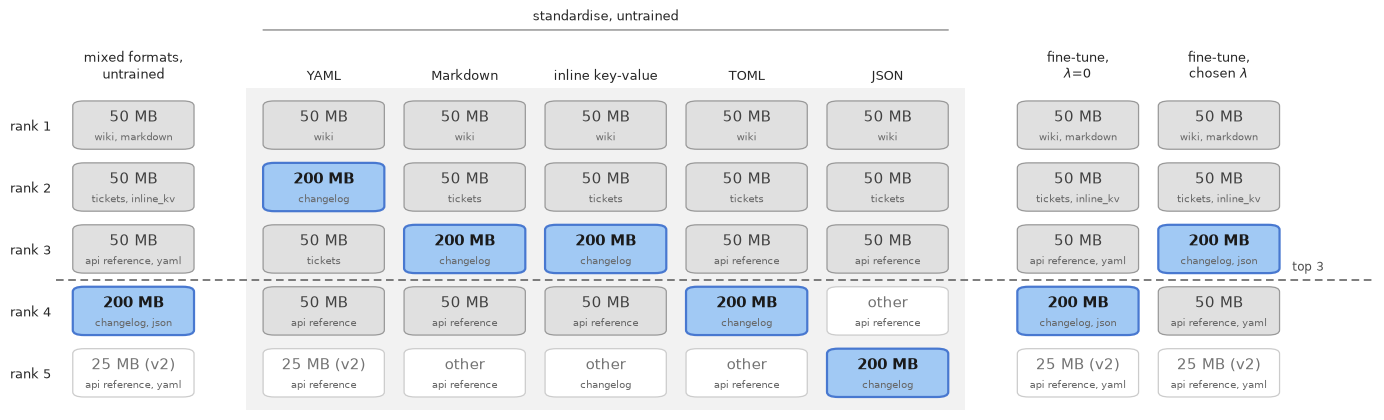

In [3]:
CARD_W, CARD_H = 0.86, 0.78
DEPTH = 5
GAP = 0.35
STYLE = {
    "200 MB": (BAR_FILL, BAR_EDGE, "0.1"),
    "50 MB": (MUTED_FILL, MUTED_EDGE, "0.25"),
}
OTHER_STYLE = ("white", "0.8", "0.45")

# Columns, with a gap either side of the standardised group.
x, at = [], 0.0
for i, condition in enumerate(shown):
    if i and (condition.handling == MIXED) != (shown[i - 1].handling == MIXED):
        at += GAP
    x.append(at)
    at += 1
group = [x[i] for i, c in enumerate(shown) if c.handling != MIXED]
cards = top[top["rank"] <= DEPTH]

fig, ax = plt.subplots(figsize=(14, 4.4))
ax.add_patch(
    Rectangle(
        (group[0] - 0.55, -DEPTH - 0.6),
        group[-1] - group[0] + 1.1,
        DEPTH + 0.2,
        facecolor="0.95",
        edgecolor="none",
        zorder=0,
    )
)
for col, condition in zip(x, shown, strict=True):
    rows = cards[cards["condition"] == condition.label]
    for _, row in rows.iterrows():
        fill, edge, ink = STYLE.get(row["claim"], OTHER_STYLE)
        y = -row["rank"]
        ax.add_patch(
            FancyBboxPatch(
                (col - CARD_W / 2, y - CARD_H / 2),
                CARD_W,
                CARD_H,
                boxstyle="round,pad=0,rounding_size=0.08",
                facecolor=fill,
                edgecolor=edge,
                linewidth=1.6 if row["key"] else 0.9,
                zorder=2,
            )
        )
        ax.text(
            col,
            y + 0.12,
            row["claim"],
            ha="center",
            va="center",
            fontsize=10.5,
            color=ink,
            weight="bold" if row["key"] else "normal",
            zorder=3,
        )
        source = row["source"].replace("_", " ")
        ax.text(
            col,
            y - 0.2,
            source if condition.handling != MIXED else f"{source}, {row['format']}",
            ha="center",
            va="center",
            fontsize=7.5,
            color="0.4",
            zorder=3,
        )

cut = -(case.k + 0.5)
ax.axhline(cut, color=RULE, lw=1.1, ls=(0, (5, 3)), zorder=1)
ax.text(
    x[-1] + 0.52,
    cut + 0.1,
    f"top {case.k}",
    ha="left",
    va="bottom",
    fontsize=8.5,
    color="0.3",
)

centre = (group[0] + group[-1]) / 2
header = ("data", "axes fraction")
ax.annotate(
    "standardise, untrained",
    (centre, 1.2),
    xycoords=header,
    ha="center",
    va="bottom",
    fontsize=9.5,
    color="0.15",
    annotation_clip=False,
)
ax.annotate(
    "",
    (group[0] - 0.45, 1.18),
    xytext=(group[-1] + 0.45, 1.18),
    xycoords=header,
    textcoords=header,
    annotation_clip=False,
    arrowprops={"arrowstyle": "-", "color": "0.5", "lw": 0.9},
)

ax.set_xlim(-0.55, x[-1] + 1.1)
ax.set_ylim(-DEPTH - 0.6, -0.4)
ax.set_xticks(x)
ax.set_xticklabels(
    [
        FORMAT_LABELS[c.handling]
        if c.handling != MIXED
        else c.label.replace(", ", ",\n")
        for c in shown
    ],
    fontsize=9.5,
)
ax.xaxis.tick_top()
ax.set_yticks([-r for r in range(1, DEPTH + 1)])
ax.set_yticklabels([f"rank {r}" for r in range(1, DEPTH + 1)], fontsize=9)
ax.grid(False)
for side in ("left", "right", "bottom", "top"):
    ax.spines[side].set_visible(False)
ax.tick_params(length=0)
save(fig, "demo_conditions")

The changelog entry ranks fourth for the untrained model on the source formats
and fourth at $\lambda$ = 0, so in both conditions the generator receives only
passages stating 50 MB. Standardised, the untrained model passes the entry on in
three of the five formats, second in YAML and third in Markdown and inline
key-value, and leaves it out in TOML and JSON, fourth and fifth. Whether
standardising helps therefore depends on which format is chosen. At the chosen
$\lambda$ the entry ranks third and the generator receives it.

## Format combinations

The source formats above are one possibility. Each of the four source systems
could equally serialise its passages in any of the five formats, giving 625
combinations, and each model ranks the passages under every one.

In [4]:
rates = case_keep_rates(case)
rates.rename(KEPT.replace("\n", " ")).round(3)

base              0.60
5fmt_lam0         0.80
5fmt_lam1         1.00
json_lam0         0.80
json_lam1         1.00
yaml_lam0         0.76
yaml_lam1         1.00
toml_lam0         0.76
toml_lam1         1.00
inline_kv_lam0    0.80
inline_kv_lam1    1.00
markdown_lam0     0.76
markdown_lam1     1.00
Name: share of the 625 format combinations with the entry in the top three, dtype: float64

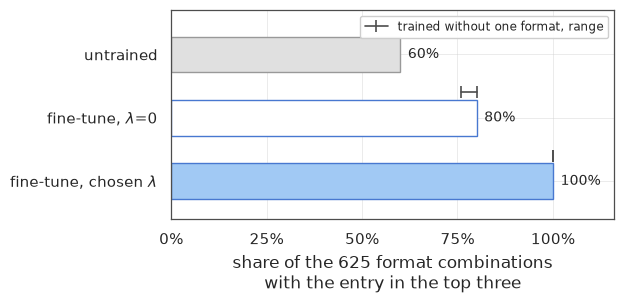

In [5]:
ARMS = [
    (BASE_ARM, "untrained", MUTED_FILL, MUTED_EDGE),
    (CONTROL_ARM, "fine-tune, $\\lambda$=0", "white", BAR_EDGE),
    (WINNER_ARM, "fine-tune, chosen $\\lambda$", BAR_FILL, BAR_EDGE),
]
# Each fine-tuned arm, retrained five times with one format withheld.
HELD = {
    CONTROL_ARM: [rates[pair[0]] for pair in HOLD_OUTS.values()],
    WINNER_ARM: [rates[pair[1]] for pair in HOLD_OUTS.values()],
}

fig, ax = plt.subplots(figsize=(6.4, 3.2))
y = np.arange(len(ARMS))
for pos, (arm, _label, fill, edge) in zip(y, ARMS, strict=True):
    ax.barh(
        pos,
        rates[arm],
        height=0.56,
        color=fill,
        edgecolor=edge,
        linewidth=1.0,
        zorder=2,
    )
    ax.text(
        rates[arm] + 0.02,
        pos,
        f"{rates[arm]:.0%}",
        va="center",
        fontsize=10,
        color="0.15",
    )
    if arm in HELD:
        low, high = min(HELD[arm]), max(HELD[arm])
        ax.plot([low, high], [pos - 0.4, pos - 0.4], color="0.3", lw=1.2, zorder=3)
        ax.plot(
            [low, high],
            [pos - 0.4, pos - 0.4],
            ls="",
            marker="|",
            ms=8,
            mec="0.3",
            mew=1.2,
            zorder=3,
        )
ax.set_yticks(y)
ax.set_yticklabels([label for _, label, _, _ in ARMS])
ax.set_ylim(len(ARMS) - 0.4, -0.7)
ax.set_xlim(0, 1.16)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel(KEPT)
ax.legend(
    handles=[
        Line2D(
            [],
            [],
            color="0.3",
            lw=1.2,
            marker="|",
            ms=8,
            mew=1.2,
            label="trained without one format, range",
        )
    ],
    loc="upper right",
    fontsize=8.5,
    frameon=True,
    facecolor="white",
    edgecolor="0.8",
    framealpha=0.95,
)
save(fig, "demo_assignments")

The changelog entry reaches the top three in 60% of the format combinations for
the untrained model, 80% at $\lambda$ = 0 and 100% at the chosen $\lambda$. Each
fine-tuned model was also trained five more times, each time without one of the
five formats, and the bar above each fine-tuned bar spans those five: 76% to 80%
at $\lambda$ = 0, and 100% for every one at the chosen $\lambda$. Fine-tuning
without the invariance term raises the share, but whether that model gives the
generator the current limit still depends on how the source systems happen to
serialise their passages, and at the chosen $\lambda$ it does not, whichever format
was left out of training.

## Variants

To check that the result does not rest on one wording of the question or one
version of the text, the comparison is repeated over every combination of the
existing wordings and passage versions. The wordings of the question are crossed
with 4,161 states of the knowledge base. A state gives each passage one of its
versions, which differ only in metadata, and may leave out any of the four
passages added to the original draft. The changelog entry and the five upload
passages that compete with it are crossed in full, giving 2,080 states, and each
is paired once with the other passages as in the question above and once with a
random draw of them. The last state is the original draft, with every passage at
its first version and none added. BM25 retrieves for each variant separately.
Wordings for which no model places the changelog entry in the top three in at
least half of the states are left out.

A sample of the wordings:

In [6]:
catalogue = load_catalogue(DEMO_ROOT)
variants = load_variants(DEMO_ROOT)
ARMS3 = [BASE_ARM, CONTROL_ARM, WINNER_ARM]
crossed_states = variants[variants["setting"] == REFERENCE]
kept = live_wordings(crossed_states, ARMS3)
print(f"{len(kept)} of {len(catalogue.wordings)} wordings kept")
print("\n".join("  " + catalogue.wordings[w]["text"] for w in kept[::4]))

22 of 26 wordings kept
  What's the maximum file size I can upload in one request to the v3 API?
  We're getting 413 Payload Too Large on a 90 MB upload, is that expected?
  What's the max body size for POST /v3/uploads?
  Do we still have to split files over 50 MB?
  Is 50 MB still the limit for one upload?
  Still a 50 MB cap on v3 uploads?


Each row below is one version of a passage's metadata, showing only the fields
that differ between its versions. Version 1 is the original. The changelog entry
that states 200 MB:

In [7]:
versions_table(catalogue, "cl-3-4-0")

,first field,component,type,title,affects,breaking,owner,docs,plans
version,,,,,,,,,
1,release,uploads,changed,,,,,,
2,release,uploads,changed,Larger single-request uploads,POST /v3/uploads,false,,,
3,release,uploads,changed,Single-request body ceiling raised from 50 MB to 200 MB,POST /v3/uploads,false,,,
4,release,uploads,changed,Larger single-request uploads,POST /v3/uploads,false,storage-team,/docs/uploads#limits,
5,release,uploads,changed,Raise the upload body limit,"POST /v3/uploads, POST /v3/upload-sessions",false,,,
6,release,uploads,changed,Raise the upload body limit,"POST /v3/uploads, POST /v3/upload-sessions",false,storage-team,/docs/uploads#limits,
7,release,uploads,changed,Raise the upload body limit,"POST /v3/uploads, POST /v3/upload-sessions",,,,
8,release,uploads,changed,Raise the upload body limit to 200 MB,"POST /v3/uploads, POST /v3/upload-sessions",false,,,
9,release,uploads,improved,Raise the upload body limit,"POST /v3/uploads, POST /v3/upload-sessions",false,,,


Ticket FH-4471, which states 50 MB:

In [8]:
versions_table(catalogue, "tk-4471")

,status,tags,resolution
version,,,
1,,,
2,closed,"uploads, 413",
3,closed,"uploads, payload-size",
4,closed,"uploads, 413",answered


Each variant is summarised by each model's share of the 625 format combinations
that place the changelog entry in the top three. The intervals are 95% and come
from a bootstrap that resamples wordings and states independently, so variants
that share a wording or a state are not counted as independent.

In [9]:
ROWS = [
    "untrained",
    "fine-tune, lambda=0",
    "fine-tune, chosen lambda",
    "chosen lambda minus lambda=0",
    "variants with chosen lambda higher",
    "variants with chosen lambda lower",
]
in_grid = crossed_states[crossed_states["wording"].isin(kept)]
grid_summary = summary(in_grid, ARMS3, CONTROL_ARM, WINNER_ARM)
grid_summary.index = ROWS
print(
    f"{in_grid['wording'].nunique()} wordings x {in_grid['state'].nunique():,} states"
)
grid_summary.round(3)

22 wordings x 2,080 states


,mean,low,high
untrained,0.303,0.211,0.409
"fine-tune, lambda=0",0.350,0.254,0.459
"fine-tune, chosen lambda",0.583,0.458,0.711
chosen lambda minus lambda=0,0.234,0.172,0.299
variants with chosen lambda higher,0.752,0.644,0.853
variants with chosen lambda lower,0.065,0.025,0.121


550 of 45,760 variants, 25 per wording


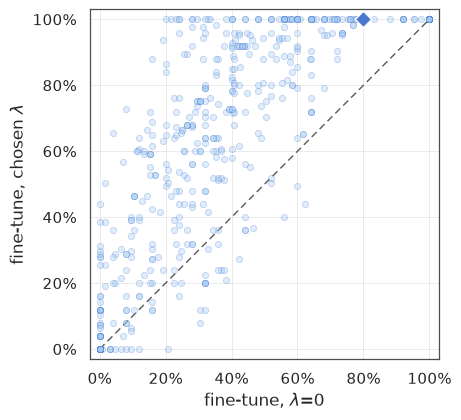

In [10]:
PER_WORDING = 25
sample = sample_variants(in_grid, PER_WORDING)
print(f"{len(sample)} of {len(in_grid):,} variants, {PER_WORDING} per wording")

fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.plot([0, 1], [0, 1], color=RULE, lw=1, ls=(0, (5, 3)), zorder=1)
ax.scatter(
    sample[CONTROL_ARM],
    sample[WINNER_ARM],
    s=20,
    color=BAR_FILL,
    edgecolor=BAR_EDGE,
    linewidth=0.5,
    alpha=0.35,
    zorder=2,
)
ax.scatter(
    [rates[CONTROL_ARM]],
    [rates[WINNER_ARM]],
    s=70,
    marker="D",
    color=BAR_EDGE,
    edgecolor="white",
    linewidth=1.0,
    zorder=3,
)
ax.set_xlim(-0.03, 1.03)
ax.set_ylim(-0.03, 1.03)
ax.set_aspect("equal")
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("fine-tune, $\\lambda$=0")
ax.set_ylabel("fine-tune, chosen $\\lambda$")
save(fig, "demo_variants")

Each point is one variant, drawn at random from the grid, 25 from each of the 22
wordings. The horizontal position is the share of the 625 format combinations in
which the model fine-tuned at $\lambda$ = 0 places the changelog entry in the top
three, and the vertical position is the same share for the model fine-tuned at
the chosen $\lambda$. A point above the dashed diagonal is a variant in which the
model trained with the invariance term places the entry in the top three under
more format combinations. The points are drawn faintly, so the darker marks are
variants that coincide, along the top edge where the chosen $\lambda$ reaches 100%
and at the origin where neither model ever does. The diamond is the question
above, at 80% and 100%.

Over all 45,760 variants, not only the sample, the chosen $\lambda$ places the entry
in the top three in 58% of format combinations, against 35% at $\lambda$ = 0 and 30%
untrained. The difference is 0.23 [0.17, 0.30], and the chosen $\lambda$ is higher
on 75% [64, 85] of the variants and lower on 6.5% [2.5, 12.1]. It reaches 100% on
22% of them, against 5.5% at $\lambda$ = 0. The case is therefore representative
of its variants rather than a point at which the ranking happens to cross the
cut.

### The other passages and the original draft

In [11]:
key = ["wording", "state"]
reference = in_grid.sort_values(key)
drawn = variants[(variants["setting"] == DRAWN) & variants["wording"].isin(kept)]
drawn = drawn.sort_values(key)
changed = (reference[ARMS3].to_numpy() != drawn[ARMS3].to_numpy()).any(axis=1)
print(f"changed by drawing the other passages: {changed.sum()} of {len(changed):,}")

original = variants[(variants["setting"] == ORIGINAL) & variants["wording"].isin(kept)]
gap = original[WINNER_ARM] - original[CONTROL_ARM]
print(f"original draft, {len(original)} wordings:")
print(
    f"  chosen lambda higher on {(gap > 0).sum()}, lower on {(gap < 0).sum()}, "
    f"level on {(gap == 0).sum()}"
)
NAMES = {
    BASE_ARM: "untrained",
    CONTROL_ARM: "fine-tune, lambda=0",
    WINNER_ARM: "fine-tune, chosen lambda",
}
per_wording(original, catalogue, ARMS3).drop(columns="stale_premise").rename(
    columns=NAMES
).round(3)

changed by drawing the other passages: 3 of 45,760
original draft, 22 wordings:
  chosen lambda higher on 7, lower on 2, level on 13


,untrained,"fine-tune, lambda=0","fine-tune, chosen lambda"
wording,,,
What's the maximum file size I can upload in one request to the v3 API?,0.000,0.000,0.00
Is there a size limit on v3 uploads?,0.000,0.000,0.00
Our 120 MB scans are being rejected by /v3/uploads. What is the actual limit?,0.000,0.000,0.00
What's the per-request upload limit on v3 now?,0.000,0.000,0.00
"We're getting 413 Payload Too Large on a 90 MB upload, is that expected?",1.000,1.000,1.00
How large a document can I send in a single upload request?,0.909,0.904,1.00
Has the upload size limit changed recently?,0.176,0.000,0.00
"Do I need upload sessions for a 150 MB file, or will a normal upload work?",0.000,0.000,0.00
What's the max body size for POST /v3/uploads?,0.000,0.000,0.00


Drawing the other passages at random changes the outcome on 3 of 45,760
variants, so the passages that do not compete for the top three do not affect
the result. On the original draft, before any of the metadata versions or added
passages, the chosen $\lambda$ is higher on seven of the 22 wordings and lower on
two, by at most 0.08. The other thirteen are level, eleven of them because
neither model places the entry in the top three under any format combination.
The direction of the effect is therefore present in the unedited knowledge base,
and the versions strengthen it rather than create it.